In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal
from optical_communication_system.plot import *

2024-08-24 20:55:09.736963: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-24 20:55:09.774317: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-24 20:55:09.774346: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-24 20:55:09.775423: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-24 20:55:09.781184: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-24 20:55:09.781820: I tensorflow/core/platform/cpu_feature_guard.cc:1

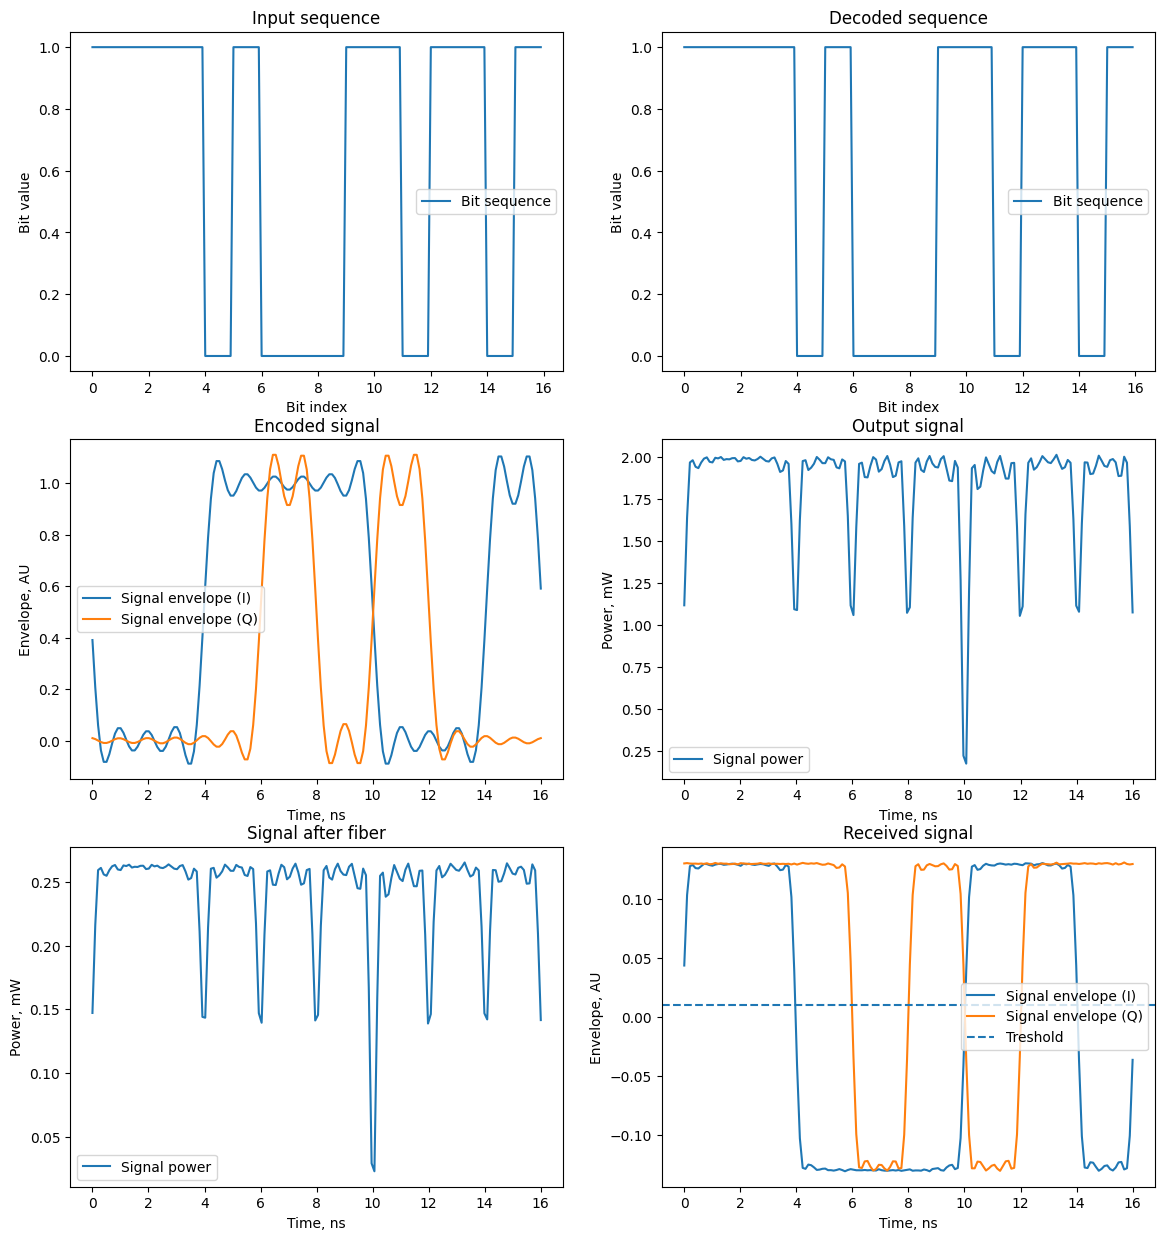

In [87]:
data_rate = 1e9
sampling_rate = data_rate * 10

lpf = ElectricalLowPassFilter(cutoff_frequency=1 * data_rate)

qam4_constellation = QAMConstellation(
    order=2,
    mapping=[
        [-1.0, -1.0], [-1.0, 1.0],
        [ 1.0, -1.0], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

qam16_constellation = QAMConstellation(
    order=4,
    mapping=[
        [-1.0, -1.0], [-1.0, -0.5], [-1.0, 0.5], [-1.0, 1.0],
        [-0.5, -1.0], [-0.5, -0.5], [-0.5, 0.5], [-0.5, 1.0],
        [ 0.5, -1.0], [ 0.5, -0.5], [ 0.5, 0.5], [ 0.5, 1.0],
        [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0, 0.5], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

encoder = System(components=[
    QAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        constellation=qam4_constellation
    ),
    MapComponent(component=lpf),
])

qam_transmitter = System(components=[
    QAMModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=1e3, frequency_count=128)
    ),
    OpticalAWGN(level=-30.0)
])

channel = OpticalFiber(attenuation=0.22, length=40.0, chromatic_dispersion=0.0)
qam_receiver = QAMReceiver(
    photodiode=System(components=[Photodiode(), lpf])
)
qam_decoder = QAMDecoder(
    data_rate=data_rate,
    constellation=qam4_constellation
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")

input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
#input_signal = rng.uniform((1024 * 4,), 0, 2, dtype=tf.int32)

system = System(components=[
    encoder,
    qam_transmitter,
    channel,
    qam_receiver,
    qam_decoder
])

encoded_signal = encoder(input_signal)
output_signal = qam_transmitter(encoded_signal)
fiber_signal = channel(output_signal)
received_signal = qam_receiver(fiber_signal)
decoded_signal = qam_decoder(received_signal)

fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(encoded_signal, encoded_ax)
plot_power(output_signal, output_ax)
plot_power(fiber_signal, fiber_ax)

plot_envelope(received_signal, received_ax)
received_ax.axhline(qam_decoder.threshold * 1000, linestyle="--", label="Treshold")

plot_bitseq(decoded_signal, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

In [88]:
ber_tester = BERTester([system])

In [89]:
ber_tester(128, 100)

<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>

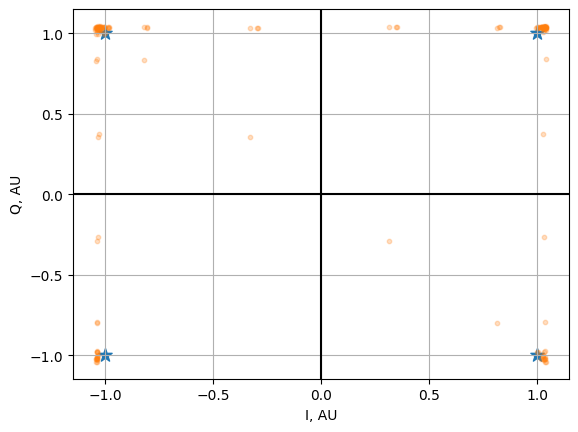

In [101]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(qam4_constellation, s=100, marker="*")
plot_iq_constellation(received_signal, s=10, iq_units=(8.0, "AU"), alpha=1 / 4)

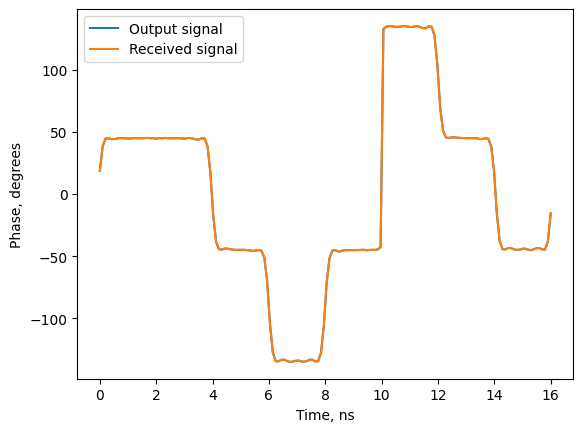

In [91]:
plot_phase(output_signal, label="Output signal")
plot_phase(received_signal, label="Received signal")
plt.legend()

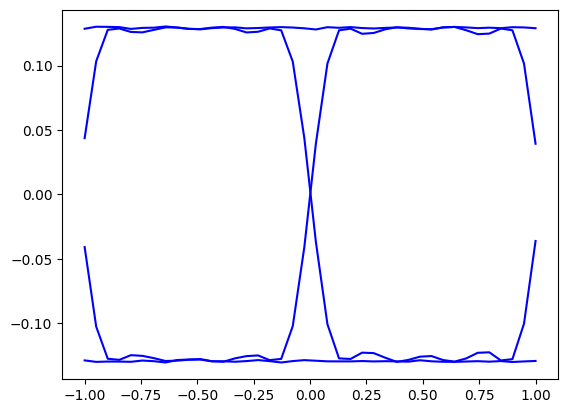

In [96]:
plot_eye_diagram(received_signal[0], color="blue", alpha=1)